# CompPhish Phishing Website Detection

A beginner-friendly study comparing URL and HTML-derived features for phishing detection.

**Dataset:** CompPhish, Version 3  
**Labels:** 0 = legitimate, 1 = phishing

## Project question

How well do URL-derived, HTML-derived, and combined features distinguish phishing websites from legitimate websites in CompPhish, and how does performance change when related domains are kept separate?

## Objectives

1. Audit the dataset, labels, feature definitions, missing values, duplicates, and repeated domains.
2. Explore how selected URL and HTML-derived features differ between the two classes.
3. Compare at least four classifiers using the same stratified evaluation split and leakage-safe preprocessing.
4. Compare URL-only, HTML-only, and combined feature sets using a consistent evaluation method.
5. Examine model errors, especially phishing samples predicted as legitimate, and interpret useful features carefully.
6. If domains can be extracted reliably, test performance when the same domain cannot appear in both training and test data.
7. Document the data source, methods, results, limitations, and instructions so the project can be reproduced from GitHub.

## Dataset background

CompPhish Version 3 contains 15,358 website samples: 7,204 phishing and 8,154 legitimate. The labels are 1 for phishing and 0 for legitimate. The dataset includes 70 precomputed features from URLs and their associated HTML, along with a mapping file and archived HTML.

The dataset page reports that phishing URLs were collected from PhishTank and OpenPhish, and legitimate URLs from the DataForSEO Top 1,000 websites list. The stated collection period is September 2024 to August 2025. The paper groups the features into brand-jacking, generic URL, and HTML-derived features.

The classes come from different collection sources, so a model might learn source-related patterns as well as phishing characteristics. Results in this project will be described as performance on this dataset and its evaluation setup—not as a guarantee about all websites.

**Sources:** [CompPhish dataset record](https://data.mendeley.com/datasets/fmbs4kp9wz/3) · [Associated paper](https://doi.org/10.1016/j.dib.2026.113219)

In [1]:
import os
print(os.getcwd())

C:\Users\hp\OneDrive\Documents\compphish-phishing-detection\notebooks


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the feature dataset
data = pd.read_excel(r"..\data\All_Features_threshold90.xlsx")

# Basic information about the dataset
print("Dataset shape:", data.shape)
data.info()

# Descriptive statistics
print(data.describe())

# First five rows
print(data.head())

# Last five rows
print(data.tail())

#Counting null values
print(data.isnull().sum())

print(data.drop(columns=["url"]).head())
print(data.drop(columns=["url"]).tail())

Dataset shape: (15358, 73)
<class 'pandas.DataFrame'>
RangeIndex: 15358 entries, 0 to 15357
Data columns (total 73 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   serial_number                  15358 non-null  int64  
 1   url                            15358 non-null  str    
 2   label                          15358 non-null  int64  
 3   brand_subdomain                15358 non-null  int64  
 4   brand_substring_domain         15358 non-null  int64  
 5   brand_typo_dom                 15358 non-null  int64  
 6   fake_tld                       15358 non-null  int64  
 7   brand_in_path_query            15358 non-null  int64  
 8   dots_path                      15358 non-null  int64  
 9   url_more_than_mean             15358 non-null  int64  
 10  domain_more_than_mean          15358 non-null  int64  
 11  gibberish                      15358 non-null  int64  
 12  domain_length                 

In [3]:
# Check the target labels
print("Label counts:")
print(data["label"].value_counts().sort_index())

print("\nLabel percentages:")
print((data["label"].value_counts(normalize=True).sort_index() * 100).round(2))

# Check missing values and duplicates
print("\nTotal missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate URLs:", data["url"].duplicated().sum())
print("Duplicate serial numbers:", data["serial_number"].duplicated().sum())

# Check for constant model features
feature_columns = [
    column for column in data.columns
    if column not in ["serial_number", "url", "label"]
]

constant_features = [
    column for column in feature_columns
    if data[column].nunique(dropna=False) == 1
]

print("\nConstant features:", constant_features)

Label counts:
label
0    8154
1    7204
Name: count, dtype: int64

Label percentages:
label
0    53.09
1    46.91
Name: proportion, dtype: float64

Total missing values: 0
Duplicate rows: 0
Duplicate URLs: 7
Duplicate serial numbers: 0

Constant features: ['brand_subdomain']


In [4]:
# Check repeated URLs without displaying the URLs themselves
repeated_urls = data[data.duplicated("url", keep=False)]

duplicate_summary = repeated_urls.groupby("url").agg(
    number_of_rows=("url", "size"),
    number_of_labels=("label", "nunique")
)

print("Unique URLs appearing more than once:", len(duplicate_summary))
print("Rows belonging to repeated URLs:", duplicate_summary["number_of_rows"].sum())
print(
    "Repeated URLs with conflicting labels:",
    (duplicate_summary["number_of_labels"] > 1).sum()
)
print(
    "Repeated URLs with the same label:",
    (duplicate_summary["number_of_labels"] == 1).sum()
)

Unique URLs appearing more than once: 7
Rows belonging to repeated URLs: 14
Repeated URLs with conflicting labels: 0
Repeated URLs with the same label: 7


In [5]:
# Keep the first row for each URL in a separate cleaned copy
data_clean = data.drop_duplicates(subset="url", keep="first").copy()

print("Original dataset shape:", data.shape)
print("After removing repeated URLs:", data_clean.shape)
print("Repeated URLs remaining:", data_clean["url"].duplicated().sum())

print("\nUpdated label counts:")
print(data_clean["label"].value_counts().sort_index())

Original dataset shape: (15358, 73)
After removing repeated URLs: (15351, 73)
Repeated URLs remaining: 0

Updated label counts:
label
0    8154
1    7197
Name: count, dtype: int64


In [6]:
# Load the mapping file and feature dictionary
mapping = pd.read_excel(r"..\data\Mapping_File.xlsx")
dictionary = pd.read_excel(r"..\data\Data_Dictionary.xlsx")

# Inspect the mapping file
print("Mapping file shape:", mapping.shape)
mapping.info()
print(mapping.head())

# Inspect the feature dictionary
print("\nDictionary shape:", dictionary.shape)
dictionary.info()
print(dictionary.head())

Mapping file shape: (15358, 3)
<class 'pandas.DataFrame'>
RangeIndex: 15358 entries, 0 to 15357
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   serial_number  15358 non-null  int64
 1   url            15358 non-null  str  
 2   label          15358 non-null  int64
dtypes: int64(2), str(1)
memory usage: 360.1 KB
   serial_number                         url  label
0              2  https://www.google.com.hk/      0
1              4       http://bongacams.com/      0
2              6      https://www.tmall.com/      0
3              7       https://www.youth.cn/      0
4              8         https://coccoc.com/      0

Dictionary shape: (72, 8)
<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 8 columns):
 #   Column                                                                                     Non-Null Count  Dtype  
---  ------                                                     

In [7]:
# Keep dictionary rows that describe an actual feature
feature_dictionary = dictionary[dictionary["Feature Name"].notna()].copy()

# Count features in each category
print("Features in each category:")
print(feature_dictionary["Category"].value_counts())

# Check that dictionary feature names match the dataset columns
dictionary_feature_names = feature_dictionary["Feature Name"].tolist()

missing_from_data = [
    name for name in dictionary_feature_names
    if name not in data.columns
]

print("\nDictionary features missing from the data:", missing_from_data)
print("Number of named features in dictionary:", len(dictionary_feature_names))

Features in each category:
Category
URL-based        42
Content-based    23
Brand-jacking     5
Name: count, dtype: int64

Dictionary features missing from the data: ['no_of_images']
Number of named features in dictionary: 70


In [8]:
# Check the spelling of this feature in both files
print("Matching column in dataset:")
print([column for column in data.columns if column.lower() == "no_of_images"])

print("\nFeature name and category in dictionary:")
print(
    feature_dictionary.loc[
        feature_dictionary["Feature Name"].str.lower() == "no_of_images",
        ["Feature Name", "Category"]
    ]
)

Matching column in dataset:
['no_of_Images']

Feature name and category in dictionary:
    Feature Name       Category
48  no_of_images  Content-based


In [9]:
# Match dictionary names to dataset columns without changing their spelling
column_lookup = {column.casefold(): column for column in data_clean.columns}

feature_dictionary["data_column"] = feature_dictionary["Feature Name"].apply(
    lambda name: column_lookup.get(name.casefold())
)

# URL-derived group includes URL-based and brand-jacking features
url_features = feature_dictionary.loc[
    feature_dictionary["Category"].isin(["URL-based", "Brand-jacking"]),
    "data_column"
].tolist()

# HTML-derived group contains content-based features
html_features = feature_dictionary.loc[
    feature_dictionary["Category"] == "Content-based",
    "data_column"
].tolist()

all_feature_columns = url_features + html_features

print("URL-derived features:", len(url_features))
print("HTML-derived features:", len(html_features))
print("Total features:", len(all_feature_columns))
print("Feature names not matched to dataset columns:",
      feature_dictionary["data_column"].isna().sum())

URL-derived features: 47
HTML-derived features: 23
Total features: 70
Feature names not matched to dataset columns: 0


label
Legitimate    8154
Phishing      7197
Name: count, dtype: int64


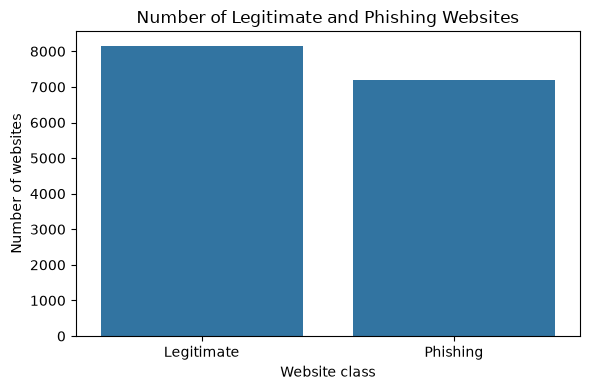

In [10]:
# Give the numeric labels readable names for the chart
class_labels = data_clean["label"].map({
    0: "Legitimate",
    1: "Phishing"
})

# Show the class counts
print(class_labels.value_counts())

# Plot the class counts
plt.figure(figsize=(6, 4))
sns.countplot(
    x=class_labels,
    order=["Legitimate", "Phishing"]
)

plt.title("Number of Legitimate and Phishing Websites")
plt.xlabel("Website class")
plt.ylabel("Number of websites")
plt.tight_layout()
plt.show()

URL length by class:
        count       mean        std   min   25%   50%   75%     max
label                                                              
0      8154.0  29.350135  78.892891  13.0  21.0  24.0  28.0  6310.0
1      7197.0  52.186189  47.175218  16.0  34.0  42.0  59.0  1111.0


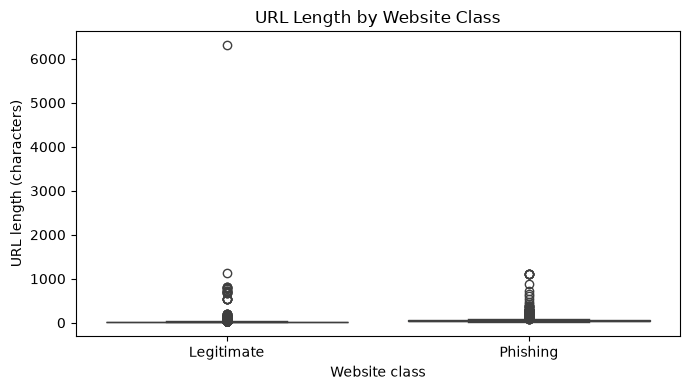

In [11]:
# Compare URL length for each class
print("URL length by class:")
print(data_clean.groupby("label")["url_length"].describe())

# Plot URL length by class
plt.figure(figsize=(7, 4))
sns.boxplot(
    x=data_clean["label"].map({
        0: "Legitimate",
        1: "Phishing"
    }),
    y=data_clean["url_length"]
)

plt.title("URL Length by Website Class")
plt.xlabel("Website class")
plt.ylabel("URL length (characters)")
plt.tight_layout()
plt.show()

In [12]:
# Check the row with the longest recorded URL
longest_row = data_clean.loc[data_clean["url_length"].idxmax()]

print("Label:", longest_row["label"])
print("Recorded URL length:", longest_row["url_length"])
print("Actual URL character count:", len(str(longest_row["url"])))

Label: 0
Recorded URL length: 6310
Actual URL character count: 6310


### URL length observation

The median URL length is 24 characters for legitimate websites and 42 characters for phishing websites. The mean is also higher for phishing websites (about 52 characters) than for legitimate websites (about 29 characters). This suggests phishing URLs tend to be longer in this dataset. The chart also shows an unusually long legitimate URL of 6,310 characters; its recorded length matches the URL string, so I kept it in the data.

Number of forms by class:
        count      mean       std  min  25%  50%  75%    max
label                                                       
0      8154.0  1.279985  4.201852  0.0  0.0  1.0  2.0  200.0
1      7197.0  0.620536  1.262111  0.0  0.0  0.0  1.0   12.0


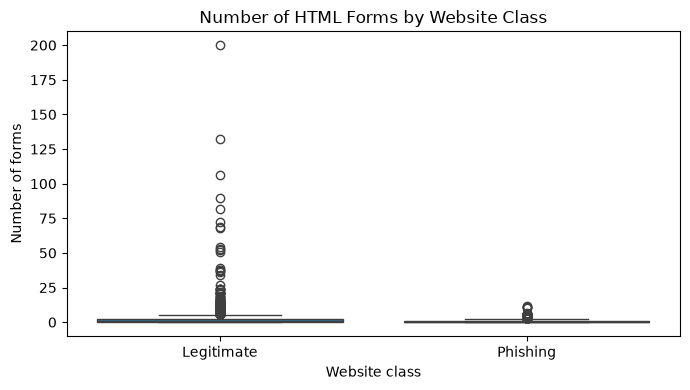

In [13]:
# Compare the number of HTML forms by class
print("Number of forms by class:")
print(data_clean.groupby("label")["no_of_forms"].describe())

# Plot the number of forms by class
plt.figure(figsize=(7, 4))
sns.boxplot(
    x=data_clean["label"].map({
        0: "Legitimate",
        1: "Phishing"
    }),
    y=data_clean["no_of_forms"]
)

plt.title("Number of HTML Forms by Website Class")
plt.xlabel("Website class")
plt.ylabel("Number of forms")
plt.tight_layout()
plt.show()

### Number of HTML forms observation

The median number of forms is 1 for legitimate websites and 0 for phishing websites. The average is also higher for legitimate websites (about 1.28) than for phishing websites (about 0.62). This shows that the number of forms alone does not separate the two classes in a simple way. One legitimate sample has 200 forms, which is much higher than the other values; I have not removed it based only on the plot.

In [14]:
# Match the feature file to the mapping file using serial_number
mapping_check = data[["serial_number", "url", "label"]].merge(
    mapping,
    on="serial_number",
    how="outer",
    suffixes=("_features", "_mapping"),
    indicator=True
)

print("Rows matched in both files:",
      (mapping_check["_merge"] == "both").sum())

print("Rows missing from one of the files:",
      (mapping_check["_merge"] != "both").sum())

print("URL mismatches:",
      (mapping_check["url_features"] != mapping_check["url_mapping"]).sum())

print("Label mismatches:",
      (mapping_check["label_features"] != mapping_check["label_mapping"]).sum())

Rows matched in both files: 15358
Rows missing from one of the files: 0
URL mismatches: 0
Label mismatches: 0


## Data quality summary

The feature file contains 15,358 rows and 73 columns: 70 features, a URL, a label, and a serial number. The mapping file matches all 15,358 records, with no URL or label mismatches. I found no missing values and no fully duplicated rows.

Seven URLs appeared twice with the same label. I kept the original data unchanged and created `data_clean` with one row per URL, leaving 15,351 rows. The feature `brand_subdomain` is constant at zero, so it will be excluded from modelling and correlation analysis.

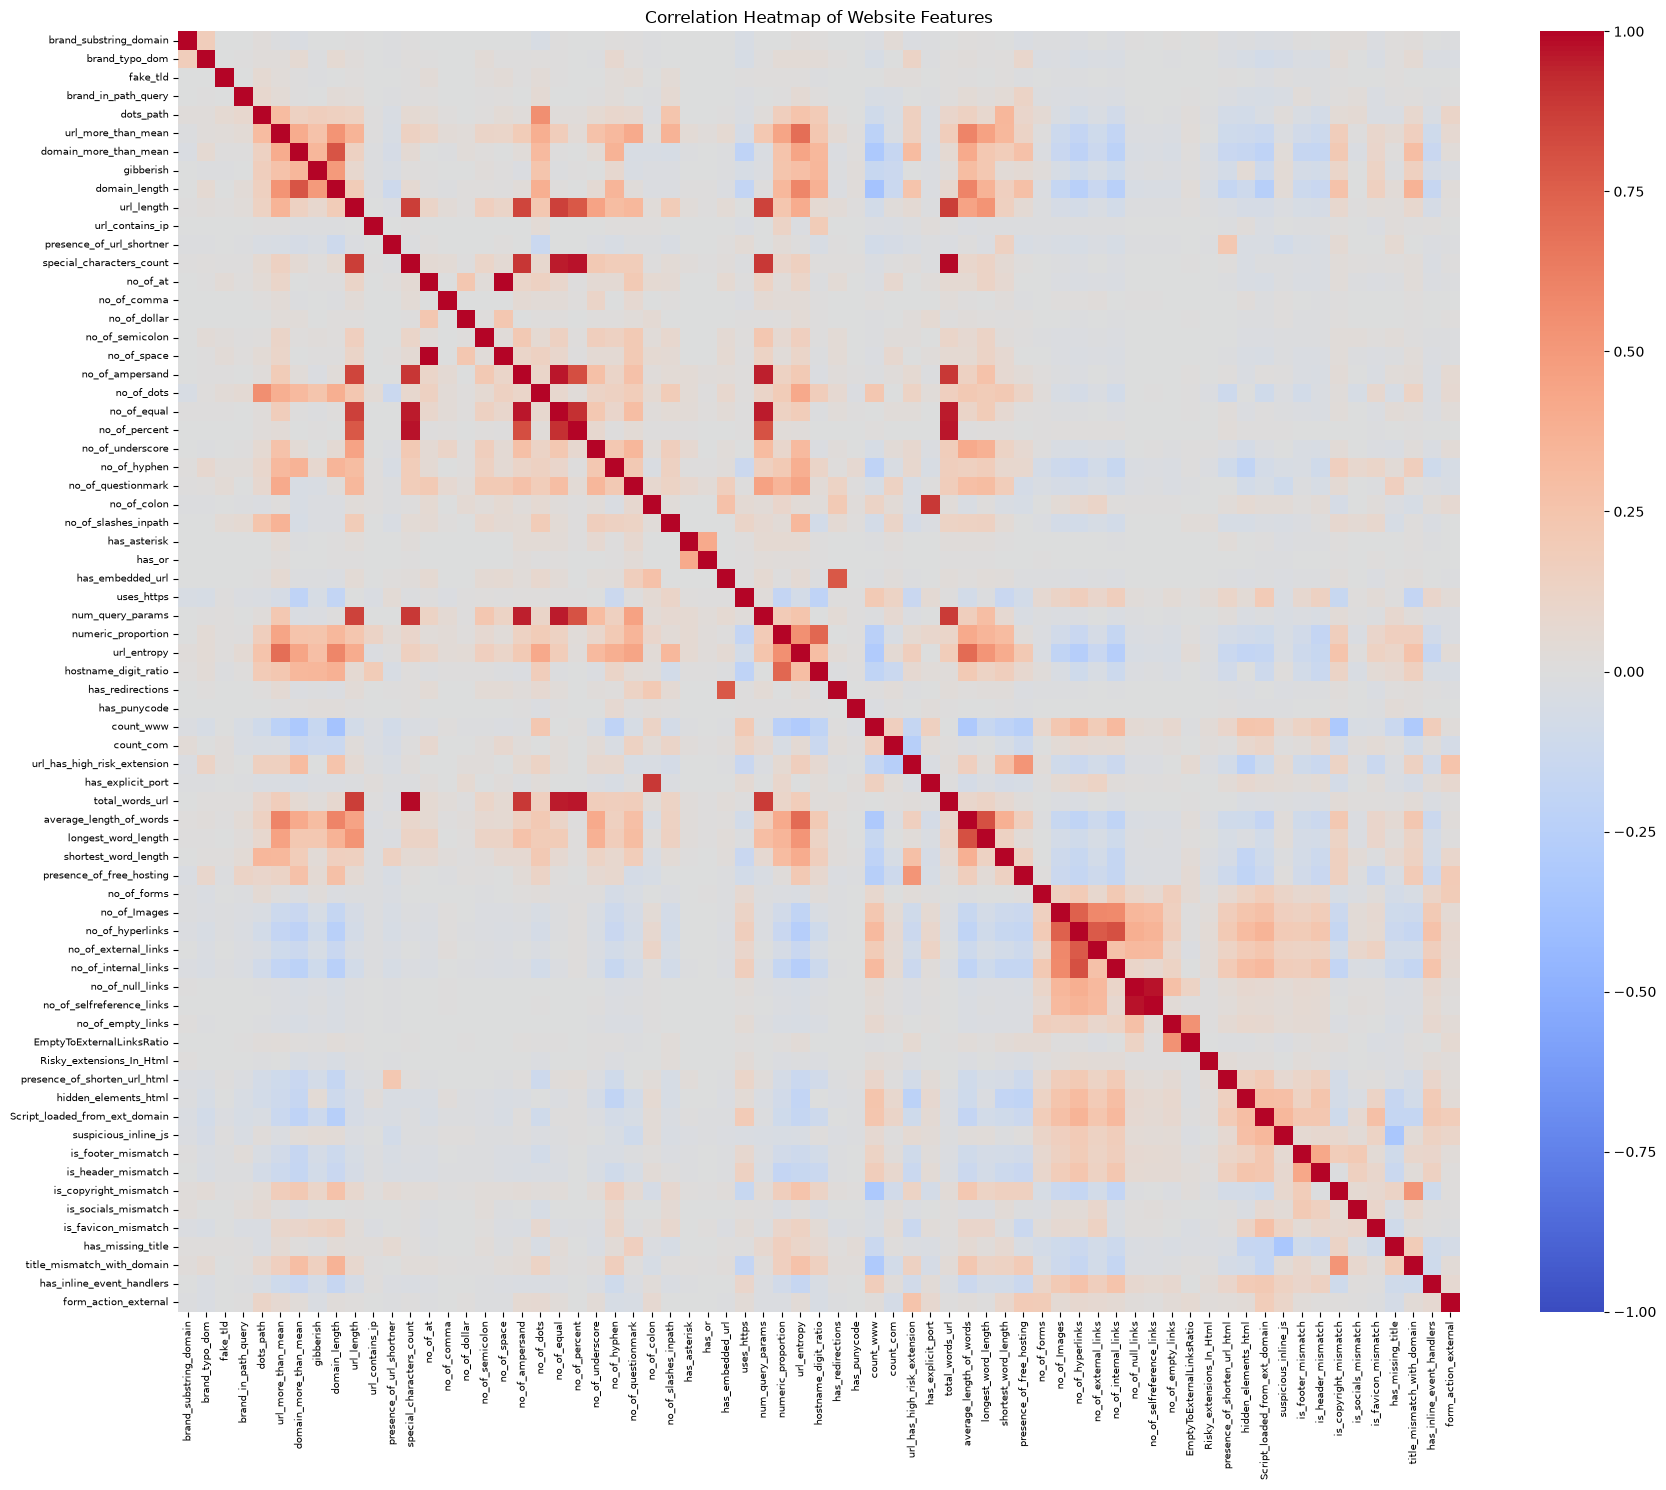

In [15]:
# Use the feature columns and exclude the constant feature
correlation_data = data_clean[all_feature_columns].drop(
    columns=constant_features,
    errors="ignore"
)

# Calculate correlations between features
correlation_matrix = correlation_data.corr()

# Plot and save the heatmap
plt.figure(figsize=(18, 15))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Website Features")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig(
    r"..\reports\figures\correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

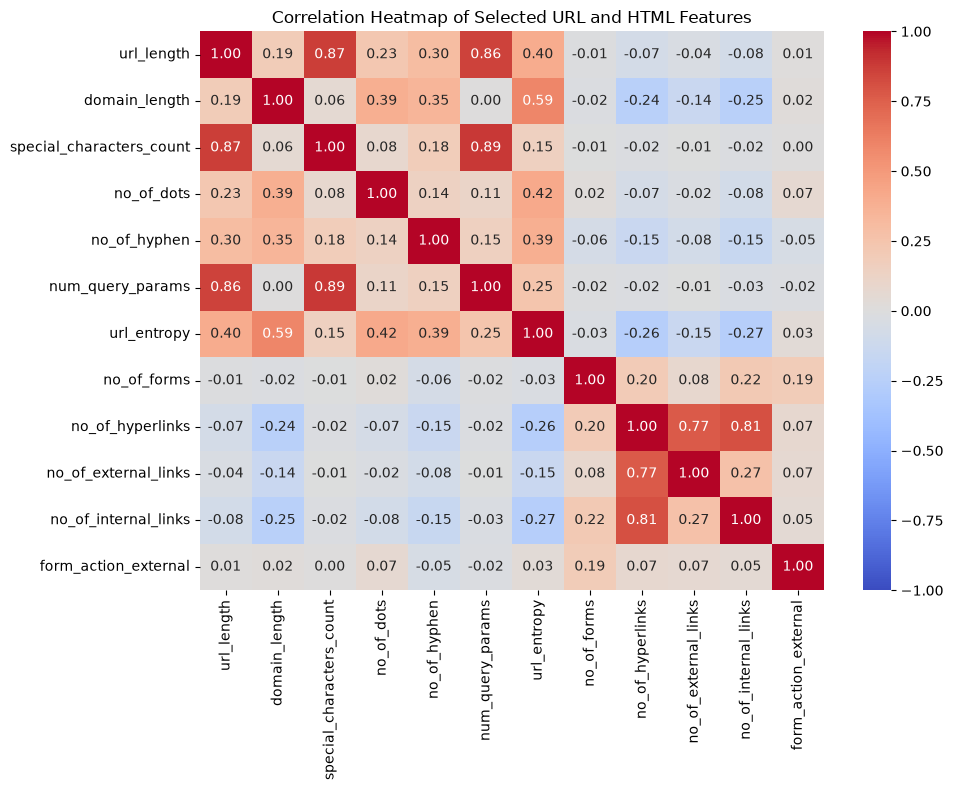

In [16]:
# Select representative URL and HTML features for a readable chart
selected_features = [
    "url_length",
    "domain_length",
    "special_characters_count",
    "no_of_dots",
    "no_of_hyphen",
    "num_query_params",
    "url_entropy",
    "no_of_forms",
    "no_of_hyperlinks",
    "no_of_external_links",
    "no_of_internal_links",
    "form_action_external"
]

# Calculate correlations for these features
selected_correlation = data_clean[selected_features].corr()

# Plot and save the focused heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    selected_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Selected URL and HTML Features")
plt.tight_layout()
plt.savefig(
    r"..\reports\figures\selected_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Correlation heatmap observation

In the selected features, URL length, special-character count, and query-parameter count are strongly positively correlated (about 0.86 to 0.89). Total hyperlinks are also positively correlated with internal and external hyperlink counts. These features contain some overlapping information. Correlation shows association, not cause, and this chart only displays the selected features.

In [17]:
from scipy.stats import ttest_ind

# Compare average URL length between the two classes
legitimate_lengths = data_clean.loc[
    data_clean["label"] == 0, "url_length"
]

phishing_lengths = data_clean.loc[
    data_clean["label"] == 1, "url_length"
]

t_statistic, p_value = ttest_ind(
    phishing_lengths,
    legitimate_lengths,
    equal_var=False
)

print("Average URL length for legitimate sites:",
      legitimate_lengths.mean())
print("Average URL length for phishing sites:",
      phishing_lengths.mean())
print("T-statistic:", t_statistic)
print("P-value:", p_value)

Average URL length for legitimate sites: 29.350134903115034
Average URL length for phishing sites: 52.186188689731836
T-statistic: 22.050255141483593
P-value: 6.797817731600238e-106


### Welch's t-test: URL length

I used Welch's independent-samples t-test to compare mean URL length between the phishing and legitimate groups. The mean was about 52.19 characters for phishing URLs and 29.35 for legitimate URLs. The test returned a t-statistic of about 22.05 and a p-value below 0.001, indicating a statistically significant difference in this dataset. The median lengths showed the same direction (42 for phishing and 24 for legitimate). A very long legitimate URL may affect the means, so URL length alone should not be treated as a reliable classifier.

In [18]:
# Features used by the models
X = data_clean.drop(
    columns=[
        "url",
        "label",
        "serial_number",
        "brand_subdomain",
        "url_more_than_mean",
        "domain_more_than_mean",
        "hostname"
    ],
    errors="ignore"
)
y = data_clean["label"]

print("Feature data shape:", X.shape)
print("\nLabel counts:")
print(y.value_counts().sort_index())

Feature data shape: (15351, 67)

Label counts:
label
0    8154
1    7197
Name: count, dtype: int64


In [19]:
from sklearn.model_selection import train_test_split

# Split the data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining label proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting label proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training feature shape: (12280, 67)
Testing feature shape: (3071, 67)

Training label proportions:
label
0    0.531
1    0.469
Name: proportion, dtype: float64

Testing label proportions:
label
0    0.531
1    0.469
Name: proportion, dtype: float64


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Create the model pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

# Train and make test predictions
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

# Measure performance, treating phishing (label 1) as the positive class
print("Accuracy:", accuracy_score(y_test, logistic_predictions))
print("Phishing precision:", precision_score(y_test, logistic_predictions, pos_label=1))
print("Phishing recall:", recall_score(y_test, logistic_predictions, pos_label=1))
print("Phishing F1-score:", f1_score(y_test, logistic_predictions, pos_label=1))

print("\nConfusion matrix")
print("Rows = actual labels (0, 1); columns = predicted labels (0, 1)")
print(confusion_matrix(y_test, logistic_predictions))

Accuracy: 0.9524584825789645
Phishing precision: 0.9468232044198895
Phishing recall: 0.9520833333333333
Phishing F1-score: 0.9494459833795014

Confusion matrix
Rows = actual labels (0, 1); columns = predicted labels (0, 1)
[[1554   77]
 [  69 1371]]


### Logistic Regression

Logistic Regression achieved 95.25% accuracy and a phishing F1-score of 94.94% on the test set. It detected 1,371 phishing samples, missed 69, and incorrectly flagged 77 legitimate samples.

In [21]:
from sklearn.tree import DecisionTreeClassifier

# Create and train the Decision Tree
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

# Predict labels for the test data
tree_predictions = tree_model.predict(X_test)

# Measure performance, treating phishing (label 1) as positive
print("Accuracy:", accuracy_score(y_test, tree_predictions))
print("Phishing precision:", precision_score(y_test, tree_predictions, pos_label=1))
print("Phishing recall:", recall_score(y_test, tree_predictions, pos_label=1))
print("Phishing F1-score:", f1_score(y_test, tree_predictions, pos_label=1))

print("\nConfusion matrix")
print("Rows = actual labels (0, 1); columns = predicted labels (0, 1)")
print(confusion_matrix(y_test, tree_predictions))

Accuracy: 0.9579941387170303
Phishing precision: 0.9536332179930795
Phishing recall: 0.9569444444444445
Phishing F1-score: 0.9552859618717504

Confusion matrix
Rows = actual labels (0, 1); columns = predicted labels (0, 1)
[[1564   67]
 [  62 1378]]


### Decision Tree

The Decision Tree achieved 95.80% accuracy and a phishing F1-score of 95.53% on the test set. It detected 1,378 phishing samples, missed 62, and incorrectly flagged 67 legitimate samples.

In [22]:
from sklearn.neighbors import KNeighborsClassifier

# Scale the features, then train KNN
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)
knn_predictions = knn_model.predict(X_test)

# Measure performance, treating phishing (label 1) as positive
print("Accuracy:", accuracy_score(y_test, knn_predictions))
print("Phishing precision:", precision_score(y_test, knn_predictions, pos_label=1))
print("Phishing recall:", recall_score(y_test, knn_predictions, pos_label=1))
print("Phishing F1-score:", f1_score(y_test, knn_predictions, pos_label=1))

print("\nConfusion matrix")
print("Rows = actual labels (0, 1); columns = predicted labels (0, 1)")
print(confusion_matrix(y_test, knn_predictions))

Accuracy: 0.9576685118853794
Phishing precision: 0.9599719101123596
Phishing recall: 0.9493055555555555
Phishing F1-score: 0.9546089385474861

Confusion matrix
Rows = actual labels (0, 1); columns = predicted labels (0, 1)
[[1574   57]
 [  73 1367]]


### K-Nearest Neighbors (KNN)

KNN achieved 95.77% accuracy and a phishing F1-score of 95.46% on the test set. It detected 1,367 phishing samples, missed 73, and incorrectly flagged 57 legitimate samples.

In [23]:
from sklearn.svm import SVC

# Scale the features, then train a linear SVM
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="linear", random_state=42))
])

svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)

# Measure performance, treating phishing (label 1) as positive
print("Accuracy:", accuracy_score(y_test, svm_predictions))
print("Phishing precision:", precision_score(y_test, svm_predictions, pos_label=1))
print("Phishing recall:", recall_score(y_test, svm_predictions, pos_label=1))
print("Phishing F1-score:", f1_score(y_test, svm_predictions, pos_label=1))

print("\nConfusion matrix")
print("Rows = actual labels (0, 1); columns = predicted labels (0, 1)")
print(confusion_matrix(y_test, svm_predictions))

Accuracy: 0.9537609899055682
Phishing precision: 0.9482044198895028
Phishing recall: 0.9534722222222223
Phishing F1-score: 0.9508310249307479

Confusion matrix
Rows = actual labels (0, 1); columns = predicted labels (0, 1)
[[1556   75]
 [  67 1373]]


### Support Vector Machine (SVM)

The linear SVM achieved 95.38% accuracy and a phishing F1-score of 95.08%. It detected 1,373 phishing samples, missed 67, and incorrectly flagged 75 legitimate samples.

In [24]:
from sklearn.ensemble import RandomForestClassifier

# Create and train the Random Forest
forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

# Measure performance, treating phishing (label 1) as positive
print("Accuracy:", accuracy_score(y_test, forest_predictions))
print("Phishing precision:", precision_score(y_test, forest_predictions, pos_label=1))
print("Phishing recall:", recall_score(y_test, forest_predictions, pos_label=1))
print("Phishing F1-score:", f1_score(y_test, forest_predictions, pos_label=1))

print("\nConfusion matrix")
print("Rows = actual labels (0, 1); columns = predicted labels (0, 1)")
print(confusion_matrix(y_test, forest_predictions))

Accuracy: 0.972972972972973
Phishing precision: 0.970853573907009
Phishing recall: 0.9715277777777778
Phishing F1-score: 0.9711905588337383

Confusion matrix
Rows = actual labels (0, 1); columns = predicted labels (0, 1)
[[1589   42]
 [  41 1399]]


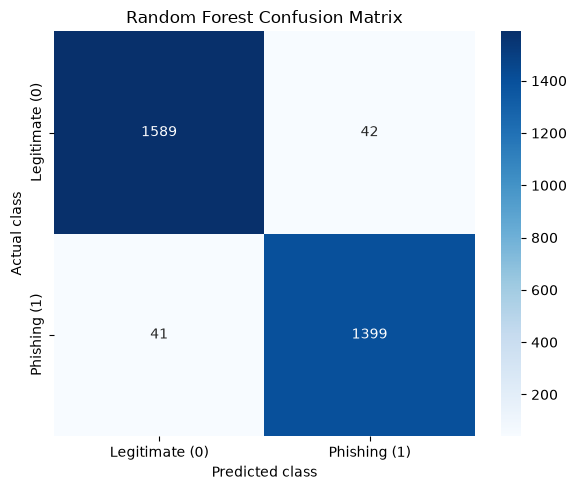

In [40]:
# Plot the Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, forest_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate (0)", "Phishing (1)"],
    yticklabels=["Legitimate (0)", "Phishing (1)"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.savefig(
    r"..\reports\figures\random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Random Forest

Random Forest achieved 97.30% accuracy and a phishing F1-score of 97.12% on the test set. It detected 1,399 phishing samples, missed 41, and incorrectly flagged 42 legitimate samples. Among the five classifiers, it had the highest phishing F1 and ROC-AUC.

In [25]:
from sklearn.metrics import roc_auc_score

# Predictions already made by each model
model_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": tree_predictions,
    "KNN": knn_predictions,
    "Linear SVM": svm_predictions,
    "Random Forest": forest_predictions
}

# Confidence scores used to calculate ROC-AUC
model_scores = {
    "Logistic Regression": logistic_model.predict_proba(X_test)[:, 1],
    "Decision Tree": tree_model.predict_proba(X_test)[:, 1],
    "KNN": knn_model.predict_proba(X_test)[:, 1],
    "Linear SVM": svm_model.decision_function(X_test),
    "Random Forest": forest_model.predict_proba(X_test)[:, 1]
}

# Calculate the same metrics for each model
comparison_rows = []

for model_name in model_predictions:
    predictions = model_predictions[model_name]

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Phishing precision": precision_score(y_test, predictions, pos_label=1),
        "Phishing recall": recall_score(y_test, predictions, pos_label=1),
        "Phishing F1": f1_score(y_test, predictions, pos_label=1),
        "ROC-AUC": roc_auc_score(y_test, model_scores[model_name])
    })

comparison_table = pd.DataFrame(comparison_rows)
print(comparison_table.round(4).to_string(index=False))

              Model  Accuracy  Phishing precision  Phishing recall  Phishing F1  ROC-AUC
Logistic Regression    0.9525              0.9468           0.9521       0.9494   0.9896
      Decision Tree    0.9580              0.9536           0.9569       0.9553   0.9579
                KNN    0.9577              0.9600           0.9493       0.9546   0.9837
         Linear SVM    0.9538              0.9482           0.9535       0.9508   0.9893
      Random Forest    0.9730              0.9709           0.9715       0.9712   0.9959


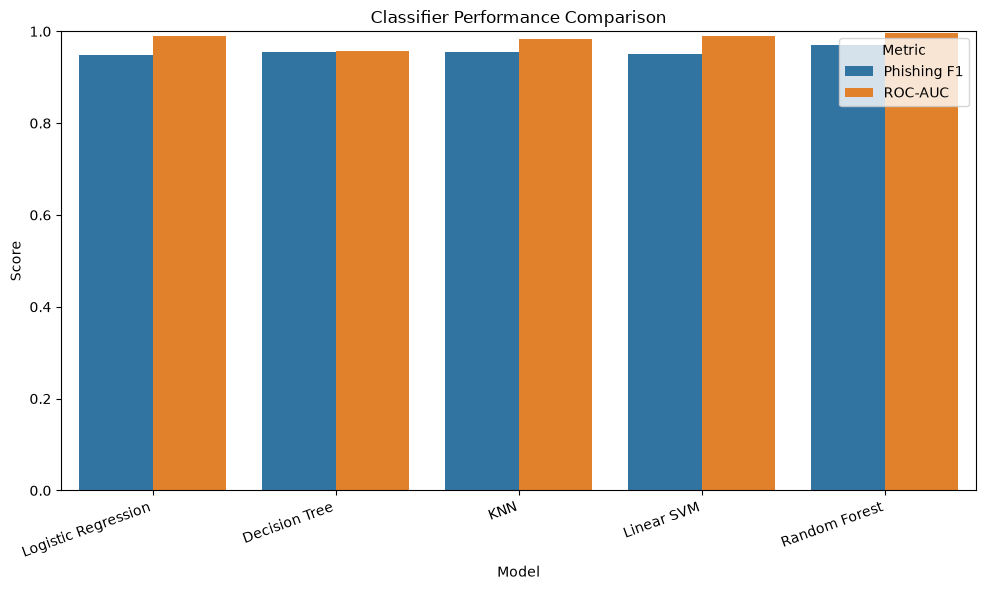

In [41]:
# Compare phishing F1 and ROC-AUC across the five classifiers
model_plot_data = comparison_table.melt(
    id_vars="Model",
    value_vars=["Phishing F1", "ROC-AUC"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=model_plot_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Classifier Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.savefig(
    r"..\reports\figures\classifier_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

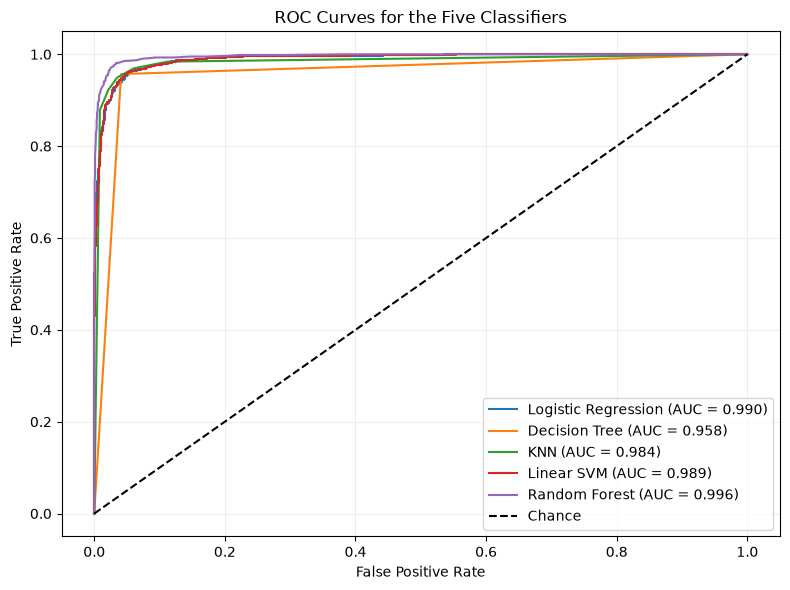

In [43]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

for model_name, scores in model_scores.items():
    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        y_test,
        scores,
        pos_label=1
    )
    auc_value = roc_auc_score(y_test, scores)

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.title("ROC Curves for the Five Classifiers")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    r"..\reports\figures\roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Model comparison

Random Forest performed best on the stratified random test split, with 97.30% accuracy, 97.12% phishing F1, 97.15% phishing recall, and 0.9959 ROC-AUC. Its confusion matrix shows 41 phishing samples missed and 42 legitimate samples incorrectly flagged. I selected it for the feature-group and error-analysis experiments. These results describe performance on this dataset and split; they do not guarantee performance on future websites.

Top 15 features:
                   Feature  Importance
      shortest_word_length    0.011390
                 count_www    0.009027
          no_of_hyperlinks    0.008007
      no_of_internal_links    0.006998
             domain_length    0.005764
                url_length    0.005672
        numeric_proportion    0.005304
      no_of_slashes_inpath    0.002838
              no_of_Images    0.002169
title_mismatch_with_domain    0.002121
      no_of_external_links    0.001984
               url_entropy    0.001968
                uses_https    0.001893
  presence_of_free_hosting    0.001879
     is_copyright_mismatch    0.001473


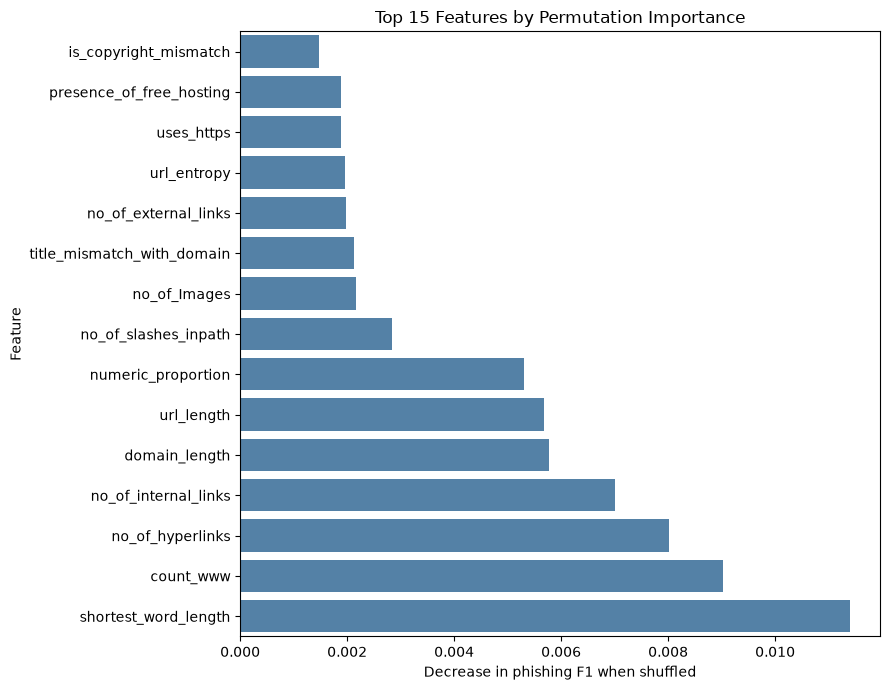

Features used by forest_model: 67
Features in X_test: 67


In [26]:
from sklearn.inspection import permutation_importance

# Measure how much each feature affects phishing F1
importance_result = permutation_importance(
    forest_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Put feature names and importance scores into a table
importance_table = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance_result.importances_mean
}).sort_values("Importance", ascending=False)

print("Top 15 features:")
print(importance_table.head(15).to_string(index=False))

# Plot the top 15 features
top_features = importance_table.head(15).sort_values("Importance")

plt.figure(figsize=(9, 7))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 15 Features by Permutation Importance")
plt.xlabel("Decrease in phishing F1 when shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(
    r"..\reports\figures\feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Features used by forest_model:", forest_model.n_features_in_)
print("Features in X_test:", X_test.shape[1])

### Feature importance

Permutation importance ranked shortest_word_length highest, followed by count_www and no_of_hyperlinks. Shuffling shortest_word_length reduced phishing F1 by about 0.011 on average. These results describe how the Random Forest used the features on this test set; they do not show that a feature causes phishing, and correlated features can share importance.

In [27]:
# Find phishing samples that the Random Forest predicted as legitimate
false_negative_mask = (
    (y_test.to_numpy() == 1) &
    (forest_predictions == 0)
)

false_negative_indices = y_test.index[false_negative_mask]
false_negatives = data_clean.loc[false_negative_indices]

# Get all phishing samples from the test set for comparison
all_phishing_indices = y_test.index[y_test.to_numpy() == 1]
all_phishing_test = data_clean.loc[all_phishing_indices]

print("Phishing samples missed:", len(false_negatives))

# Compare selected features; for binary features, the mean is the proportion with value 1
features_to_check = [
    "count_www",
    "shortest_word_length",
    "url_length",
    "no_of_hyperlinks",
    "no_of_external_links",
    "uses_https",
    "brand_typo_dom"
]

error_comparison = pd.DataFrame({
    "All phishing test samples": all_phishing_test[features_to_check].mean(),
    "Missed phishing samples": false_negatives[features_to_check].mean()
})

print("\nFeature averages for all phishing samples vs. missed phishing samples:")
print(error_comparison.round(2))

Phishing samples missed: 41

Feature averages for all phishing samples vs. missed phishing samples:
                      All phishing test samples  Missed phishing samples
count_www                                  0.05                     0.22
shortest_word_length                       1.09                     0.17
url_length                                53.23                    27.24
no_of_hyperlinks                          24.06                   103.02
no_of_external_links                      14.45                    48.76
uses_https                                 0.79                     0.71
brand_typo_dom                             0.02                     0.05


In [28]:
# Compare medians to reduce the influence of extreme values
numeric_features_to_check = [
    "count_www",
    "shortest_word_length",
    "url_length",
    "no_of_hyperlinks",
    "no_of_external_links"
]

median_comparison = pd.DataFrame({
    "All phishing test samples": all_phishing_test[numeric_features_to_check].median(),
    "Missed phishing samples": false_negatives[numeric_features_to_check].median()
})

print(median_comparison)

                      All phishing test samples  Missed phishing samples
count_www                                   0.0                      0.0
shortest_word_length                        1.0                      0.0
url_length                                 43.0                     26.0
no_of_hyperlinks                            5.0                     59.0
no_of_external_links                        2.0                      8.0


### False-negative analysis

The Random Forest missed 41 phishing samples. Compared with all phishing samples in the test set, the missed samples had a lower median URL length (26 versus 43 characters) and higher median hyperlink counts (59 versus 5 total hyperlinks; 8 versus 2 external links). The median count_www was zero in both groups. These are descriptive patterns among the missed samples; they do not prove why the model made those predictions.

In [29]:
from urllib.parse import urlparse

# Extract the hostname from each URL
data_clean["hostname"] = data_clean["url"].apply(
    lambda url: urlparse(str(url)).hostname
)

# Make hostnames lowercase and remove a leading "www."
data_clean["hostname"] = (
    data_clean["hostname"]
    .str.lower()
    .str.replace(r"^www\.", "", regex=True)
)

print("Rows without a hostname:", data_clean["hostname"].isna().sum())
print("Unique hostnames:", data_clean["hostname"].nunique())
print("Rows with repeated hostnames:", data_clean["hostname"].duplicated().sum())

Rows without a hostname: 0
Unique hostnames: 13417
Rows with repeated hostnames: 1934


In [30]:
from sklearn.model_selection import StratifiedGroupKFold

# Match each feature row with its hostname
host_groups = data_clean.loc[X.index, "hostname"]

# Make a 5-part split and use one part as the test set
group_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_index, test_index = next(
    group_splitter.split(X, y, groups=host_groups)
)

X_train_host = X.iloc[train_index]
X_test_host = X.iloc[test_index]
y_train_host = y.iloc[train_index]
y_test_host = y.iloc[test_index]

# Check whether any hostname occurs in both sets
train_hosts = set(host_groups.iloc[train_index])
test_hosts = set(host_groups.iloc[test_index])

print("Training shape:", X_train_host.shape)
print("Testing shape:", X_test_host.shape)
print("Hostnames shared between sets:", len(train_hosts & test_hosts))

print("\nTraining label proportions:")
print(y_train_host.value_counts(normalize=True).sort_index().round(3))

print("\nTesting label proportions:")
print(y_test_host.value_counts(normalize=True).sort_index().round(3))

Training shape: (12281, 67)
Testing shape: (3070, 67)
Hostnames shared between sets: 0

Training label proportions:
label
0    0.531
1    0.469
Name: proportion, dtype: float64

Testing label proportions:
label
0    0.531
1    0.469
Name: proportion, dtype: float64


In [31]:
# Train a new Random Forest using the host-based training set
host_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

host_forest_model.fit(X_train_host, y_train_host)
host_predictions = host_forest_model.predict(X_test_host)

# Evaluate on hostnames kept out of training
print("Accuracy:", accuracy_score(y_test_host, host_predictions))
print("Phishing precision:",
      precision_score(y_test_host, host_predictions, pos_label=1))
print("Phishing recall:",
      recall_score(y_test_host, host_predictions, pos_label=1))
print("Phishing F1-score:",
      f1_score(y_test_host, host_predictions, pos_label=1))

print("\nConfusion matrix")
print("Rows = actual labels (0, 1); columns = predicted labels (0, 1)")
print(confusion_matrix(y_test_host, host_predictions))

Accuracy: 0.968729641693811
Phishing precision: 0.9647058823529412
Phishing recall: 0.9687282835302293
Phishing F1-score: 0.9667128987517337

Confusion matrix
Rows = actual labels (0, 1); columns = predicted labels (0, 1)
[[1580   51]
 [  45 1394]]


In [32]:
host_scores = host_forest_model.predict_proba(X_test_host)[:, 1]

print(
    "Host-based ROC-AUC:",
    roc_auc_score(y_test_host, host_scores)
)

Host-based ROC-AUC: 0.9943568601569062


### Host-based evaluation

I kept each normalized hostname entirely in either the training or test set; no hostname was shared between the two. On this split, Random Forest achieved 96.87% accuracy, 96.67% phishing F1, and 0.9944 ROC-AUC. It missed 45 phishing samples and incorrectly flagged 51 legitimate samples.

The random-split results were slightly higher, but the test samples differ, so the difference cannot be attributed to hostname grouping alone. This is a hostname-based check: different subdomains may still be treated as separate hosts.

In [33]:
# Prepare URL-only, HTML-only, and combined feature sets
X_url = data_clean.loc[X.index, url_features].drop(
    columns=constant_features + [
        "url_more_than_mean",
        "domain_more_than_mean"
    ],
    errors="ignore"
)
X_html = data_clean.loc[X.index, html_features]

X_all = X

print("URL-only feature shape:", X_url.shape)
print("HTML-only feature shape:", X_html.shape)
print("Combined feature shape:", X_all.shape)

URL-only feature shape: (15351, 44)
HTML-only feature shape: (15351, 23)
Combined feature shape: (15351, 67)


In [34]:
# Use the same training and test rows with URL features only
X_url_train = X_url.loc[X_train.index]
X_url_test = X_url.loc[X_test.index]

# Train Random Forest using URL features
url_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

url_forest_model.fit(X_url_train, y_train)
url_predictions = url_forest_model.predict(X_url_test)
url_scores = url_forest_model.predict_proba(X_url_test)[:, 1]

# Evaluate the URL-only model
print("Accuracy:", accuracy_score(y_test, url_predictions))
print("Phishing precision:", precision_score(y_test, url_predictions, pos_label=1))
print("Phishing recall:", recall_score(y_test, url_predictions, pos_label=1))
print("Phishing F1-score:", f1_score(y_test, url_predictions, pos_label=1))
print("ROC-AUC:", roc_auc_score(y_test, url_scores))

print("\nConfusion matrix")
print("Rows = actual labels (0, 1); columns = predicted labels (0, 1)")
print(confusion_matrix(y_test, url_predictions))

Accuracy: 0.9524584825789645
Phishing precision: 0.9455922865013774
Phishing recall: 0.9534722222222223
Phishing F1-score: 0.9495159059474412
ROC-AUC: 0.9877637696709586

Confusion matrix
Rows = actual labels (0, 1); columns = predicted labels (0, 1)
[[1552   79]
 [  67 1373]]


In [35]:
# Use the same training and test rows with HTML features only
X_html_train = X_html.loc[X_train.index]
X_html_test = X_html.loc[X_test.index]

# Train Random Forest using HTML features
html_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

html_forest_model.fit(X_html_train, y_train)
html_predictions = html_forest_model.predict(X_html_test)
html_scores = html_forest_model.predict_proba(X_html_test)[:, 1]

# Evaluate the HTML-only model
print("Accuracy:", accuracy_score(y_test, html_predictions))
print("Phishing precision:", precision_score(y_test, html_predictions, pos_label=1))
print("Phishing recall:", recall_score(y_test, html_predictions, pos_label=1))
print("Phishing F1-score:", f1_score(y_test, html_predictions, pos_label=1))
print("ROC-AUC:", roc_auc_score(y_test, html_scores))

print("\nConfusion matrix")
print("Rows = actual labels (0, 1); columns = predicted labels (0, 1)")
print(confusion_matrix(y_test, html_predictions))

Accuracy: 0.931943992184956
Phishing precision: 0.9509157509157509
Phishing recall: 0.9013888888888889
Phishing F1-score: 0.9254901960784314
ROC-AUC: 0.9823376507255263

Confusion matrix
Rows = actual labels (0, 1); columns = predicted labels (0, 1)
[[1564   67]
 [ 142 1298]]


In [36]:
# Store predictions and confidence scores for each feature set
feature_group_results = {
    "URL-only": (url_predictions, url_scores),
    "HTML-only": (html_predictions, html_scores),
    "Combined": (
        forest_predictions,
        forest_model.predict_proba(X_test)[:, 1]
    )
}

# Calculate the same metrics for each feature set
feature_group_rows = []

for group_name in feature_group_results:
    predictions, scores = feature_group_results[group_name]
    matrix = confusion_matrix(y_test, predictions)

    feature_group_rows.append({
        "Feature set": group_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Phishing precision": precision_score(y_test, predictions, pos_label=1),
        "Phishing recall": recall_score(y_test, predictions, pos_label=1),
        "Phishing F1": f1_score(y_test, predictions, pos_label=1),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "False negatives": matrix[1, 0],
        "False positives": matrix[0, 1]
    })

feature_group_table = pd.DataFrame(feature_group_rows)
print(feature_group_table.round(4).to_string(index=False))

Feature set  Accuracy  Phishing precision  Phishing recall  Phishing F1  ROC-AUC  False negatives  False positives
   URL-only    0.9525              0.9456           0.9535       0.9495   0.9878               67               79
  HTML-only    0.9319              0.9509           0.9014       0.9255   0.9823              142               67
   Combined    0.9730              0.9709           0.9715       0.9712   0.9959               41               42


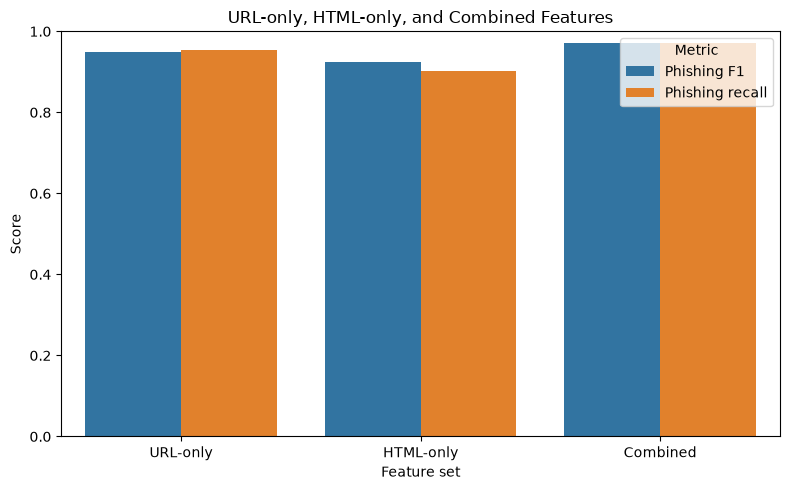

In [42]:
# Compare phishing F1 and recall for the three feature sets
feature_plot_data = feature_group_table.melt(
    id_vars="Feature set",
    value_vars=["Phishing F1", "Phishing recall"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_plot_data,
    x="Feature set",
    y="Score",
    hue="Metric"
)

plt.title("URL-only, HTML-only, and Combined Features")
plt.xlabel("Feature set")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Metric")
plt.tight_layout()
plt.savefig(
    r"..\reports\figures\feature_group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### URL-only, HTML-only, and combined comparison

On the stratified random test split, the combined feature set performed best, with 97.30% accuracy, 97.12% phishing F1, and 41 false negatives. URL-only features achieved 95.25% accuracy and 94.95% phishing F1, outperforming HTML-only features on accuracy, recall, and F1. HTML-only features had slightly higher precision than URL-only features, but missed 142 phishing samples. The combined model missed 26 fewer phishing samples than the URL-only model. These findings apply to this dataset and split; they do not establish performance on future websites.

## Reliability check: phishing-mean features

The data dictionary defines `url_more_than_mean` and `domain_more_than_mean` using mean lengths calculated from phishing examples. Because the supplied feature file contains these precomputed values and does not document training-only thresholds, I excluded both features from the model inputs as a precaution against label-informed information.

The corrected Random Forest still achieved 97.30% accuracy, 97.12% phishing F1, and 0.9959 ROC-AUC. This shows the two excluded features were not necessary for the reported result. It does not rule out other dataset limitations, such as source-related patterns.

In [37]:
suspect_features = ["url_more_than_mean", "domain_more_than_mean"]

for feature in suspect_features:
    if feature in data_clean.columns:
        print("\n", feature)
        print(data_clean[feature].value_counts(dropna=False))
    else:
        print("\n", feature, "is not in the dataset")


 url_more_than_mean
url_more_than_mean
0    12726
1     2625
Name: count, dtype: int64

 domain_more_than_mean
domain_more_than_mean
0    12270
1     3081
Name: count, dtype: int64


In [38]:
for feature in suspect_features:
    print("\n", feature)
    print(pd.crosstab(
        data_clean["label"],
        data_clean[feature],
        normalize="index"
    ).round(3))


 url_more_than_mean
url_more_than_mean      0      1
label                           
0                   0.964  0.036
1                   0.677  0.323

 domain_more_than_mean
domain_more_than_mean      0      1
label                              
0                      0.994  0.006
1                      0.578  0.422


In [39]:
dictionary.loc[
    dictionary["Feature Name"].isin(suspect_features),
    [
        "Feature Name",
        "Description",
        "Computational Rule/Threshold/Criteria"
    ]
].to_string(index=False)

'         Feature Name                                                Description                                                                  Computational Rule/Threshold/Criteria\n   url_more_than_mean       URL length greater than mean length of phishing URLs       Mean length of all the phishing urls is computed. Value returned in 1 if the url length is more \ndomain_more_than_mean Domain length greater than mean length of phishing domains Mean length of all the phishing domains is computed. Value returned in 1 if the domain length is more '